# Занятие 2. Прямая и обратная задачи о положении — демонстрации

Учебник: Зенкевич С. Л., Ющенко А. С. «Основы управления манипуляционными роботами», гл. 2.
Библиотека `kinlib.py` — классы `Frame`, `RobotSerial`, `RobotTrajectory` из ноутбука «ПЗК_и_ОЗК_на_Python» плюс помощники для плоских механизмов.

| № | Демонстрация | Слайды | Книга |
|---|---|---|---|
| 1 | Матрицы Денавита — Хартенберга и ПЗК двухзвенника | 5–7 | пример 2.1 |
| 2 | ПЗК шестизвенного робота, проверка «понятной» конфигурации | 8–9 | примеры 2.2–2.4 |
| 3 | Рабочая зона плоского 2R с ограничениями, оценка площади | 12–14 | пример 2.5, с. 84 |
| 4 | Рабочее пространство 6R методом Монте-Карло, показатель Ли — Янга | 14–15 | с. 80–85 |
| 5 | Коэффициент сервиса и сервис плоского 3R | 17–19 | пример 2.8 |
| 6 | ОЗК двухзвенника: две ветви | 29 | пример 2.10 |
| 7 | Численная ОЗК: сходимость J⁺, DLS и Jᵀ, разные ветви | 37–39 | п. 2.3.3 |
| 8 | Недостижимая цель и цепочка близких целей | 39 | с. 110 |
| 9 | Интерактив: ползунки обобщённых координат | — | — |

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('.'))          # kinlib.py лежит рядом с ноутбуком
import numpy as np
import matplotlib.pyplot as plt
from kinlib import *
np.set_printoptions(precision=4, suppress=True)
plt.rcParams['figure.dpi'] = 100
%matplotlib inline

## 1. Матрицы Денавита — Хартенберга и ПЗК плоского двухзвенника (пример 2.1)

Матрица звена $A_i(d_i, a_i, q_i, \alpha_i)$ — формула (2.8). Для плоского двухзвенника $\alpha_i = 0,\ d_i = 0$.
Проверим произведение $T_2 = A_1 A_2$ и явные формулы $x = a_1 c_1 + a_2 c_{12}$, $y = a_1 s_1 + a_2 s_{12}$.

A1 =
 [[ 0.866 -0.5    0.     0.866]
 [ 0.5    0.866 -0.     0.5  ]
 [ 0.     0.     1.     0.   ]
 [ 0.     0.     0.     1.   ]] 
A2 =
 [[ 0.707 -0.707  0.     0.495]
 [ 0.707  0.707 -0.     0.495]
 [ 0.     0.     1.     0.   ]
 [ 0.     0.     0.     1.   ]] 
T2 = A1*A2 =
 [[ 0.259 -0.966  0.     1.047]
 [ 0.966  0.259  0.     1.176]
 [ 0.     0.     1.     0.   ]
 [ 0.     0.     0.     1.   ]]
явные формулы: x = 1.0472, y = 1.1761, phi = 75.0°
из матрицы:    x = 1.0472, y = 1.1761, phi = 75.0°


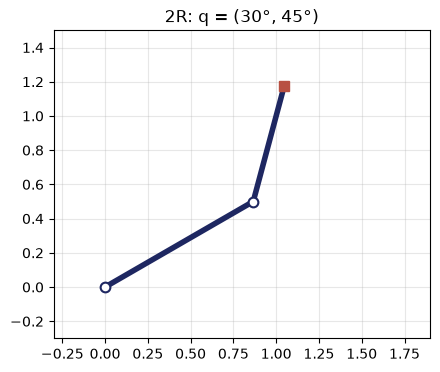

In [2]:
a1, a2 = 1.0, 0.7
q1, q2 = np.radians(30), np.radians(45)
A1 = Frame.from_dh((0, a1, 0, q1))     # (d, a, alpha, theta)
A2 = Frame.from_dh((0, a2, 0, q2))
T2 = A1 * A2
print('A1 =\n', A1, '\nA2 =\n', A2, '\nT2 = A1*A2 =\n', T2)
print('явные формулы: x = %.4f, y = %.4f, phi = %.1f°' % (a1*np.cos(q1) + a2*np.cos(q1+q2), a1*np.sin(q1) + a2*np.sin(q1+q2), np.degrees(q1+q2)))
print('из матрицы:    x = %.4f, y = %.4f, phi = %.1f°' % (T2[0,3], T2[1,3], np.degrees(np.arctan2(T2[1,0], T2[0,0]))))

fig, ax = plt.subplots(figsize=(5, 4))
pts = draw_arm2d(ax, [q1, q2], [a1, a2])
ax.set_aspect('equal'); ax.grid(alpha=.3); ax.set_xlim(-0.3, 1.9); ax.set_ylim(-0.3, 1.5)
ax.set_title('2R: q = (30°, 45°)'); plt.show()

## 2. ПЗК шестизвенного робота (таблица ДХ типа UR10)

`RobotSerial` перемножает матрицы рекуррентно: $T_i = T_{i-1}A_i$ (формула (2.3)); `axis_frames` — положения всех звеньев.
Приём отладки со слайда 8: подставить конфигурацию, в которой ответ очевиден.

таблица ДХ | d | a | alpha | theta0 |
 [[ 0.163   0.      1.5708  0.    ]
 [ 0.      0.632   3.1416  1.5708]
 [ 0.      0.6005  3.1416  0.    ]
 [ 0.2013  0.     -1.5708 -1.5708]
 [ 0.1025  0.      1.5708  0.    ]
 [ 0.094   0.      0.      0.    ]]
q = 0: положение схвата p = [ 0.     -0.2953  1.498 ] 
ориентация R =
 [[ 1.  0. -0.]
 [-0.  0. -1.]
 [ 0.  1.  0.]]
сумма вылетов вдоль руки a2 + a3 = 1.2325 ; смещения d1, d4, d5, d6 = [0.163  0.2013 0.1025 0.094 ]

q = [ 0.      0.     -0.7854  0.      0.      0.    ] 
T_6 =
 [[ 0.707 -0.707 -0.    -0.497]
 [-0.     0.    -1.    -0.295]
 [ 0.707  0.707 -0.     1.292]
 [ 0.     0.     0.     1.   ]]
T_1: p = [0.    0.    0.163]
T_2: p = [0.    0.    0.795]
T_3: p = [-0.4246  0.      1.2196]
T_4: p = [-0.4246 -0.2013  1.2196]
T_5: p = [-0.4971 -0.2013  1.2921]
T_6: p = [-0.4971 -0.2953  1.2921]


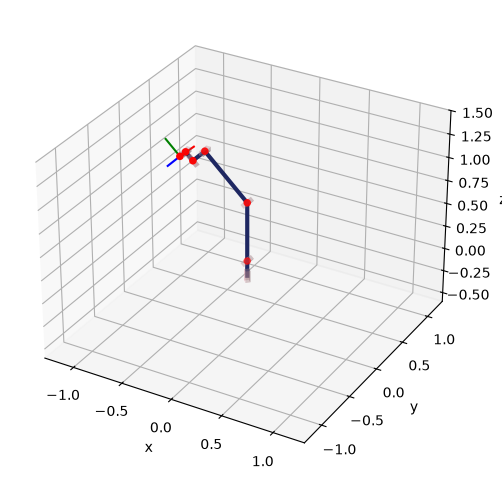

In [3]:
robot = make_ur()
print('таблица ДХ | d | a | alpha | theta0 |\n', UR_DH)
T = robot.forward(np.zeros(6))
print('q = 0: положение схвата p =', T.t_3_1.ravel(), '\nориентация R =\n', T.r_3_3)
print('сумма вылетов вдоль руки a2 + a3 =', UR_DH[1,1] + UR_DH[2,1], '; смещения d1, d4, d5, d6 =', UR_DH[[0,3,4,5],0])

q = np.array([0., 0., -0.25*np.pi, 0., 0., 0.])
T = robot.forward(q)
print('\nq =', q, '\nT_6 =\n', T)
for i, f in enumerate(robot.axis_frames, 1):
    print('T_%d: p = %s' % (i, f.t_3_1.ravel()))
robot.show()

## 3. Рабочая зона плоского 2R с ограничениями (пример 2.5)

Область $S_q$ — прямоугольник ограничений, рабочая зона $S_r$ — её образ при отображении $\mathbf r = \mathbf r(q_1, q_2)$.
Граница составлена из дуг: $\Gamma_1$ радиуса $l_1+l_2$, $\Gamma_2$ радиуса $l_2$, $\Gamma_3$ радиуса $l_1$. Площадь оцениваем числом занятых ячеек решётки $S \approx M\delta^2$.

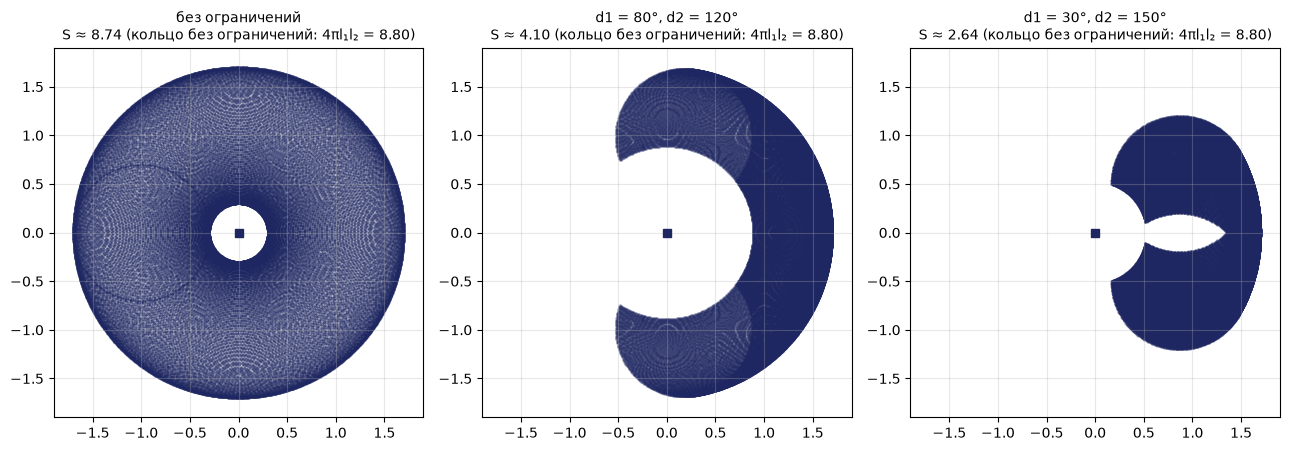

In [4]:
l = (1.0, 0.7)
cases = [('без ограничений', (-np.pi, np.pi), (-np.pi, np.pi)),
         ('d1 = 80°, d2 = 120°', np.radians((-80, 80)), np.radians((-120, 120))),
         ('d1 = 30°, d2 = 150°', np.radians((-30, 30)), np.radians((-150, 150)))]
fig, axs = plt.subplots(1, 3, figsize=(13, 4.3))
for ax, (name, lim1, lim2) in zip(axs, cases):
    X, Y = workspace_2r(l, lim1, lim2, n=250)
    ax.scatter(X, Y, s=1, color=NAVY, alpha=.3, rasterized=True)
    S = area_from_points(X, Y, 0.02)
    ax.plot(0, 0, 's', color=NAVY)
    ax.set_aspect('equal'); ax.set_xlim(-1.9, 1.9); ax.set_ylim(-1.9, 1.9); ax.grid(alpha=.3)
    ax.set_title('%s\nS ≈ %.2f (кольцо без ограничений: 4πl₁l₂ = %.2f)' % (name, S, 4*np.pi*l[0]*l[1]), fontsize=10)
plt.tight_layout(); plt.show()

## 4. Рабочее пространство 6R методом Монте-Карло и показатель Ли — Янга

Решаем ПЗК для $n$ случайных $\mathbf q$ внутри ограничений (с. 84–85). Объём — по числу занятых кубических ячеек $V \approx M\delta^3$,
обобщённая длина $L = \sum a_i + \sum d_i$, показатель Ли — Янга $V_L = V/L^3$ (максимум $4\pi/3 \approx 4{,}19$ у «сферического» манипулятора).

точек: 40000, объём V ≈ 3.401 м³, L = 1.793 м, V_L = V/L³ = 0.59, V_N = V_L/(4π/3) = 0.141
пределы досягаемости: R_max = 1.547 м, z от -1.21 до 1.53


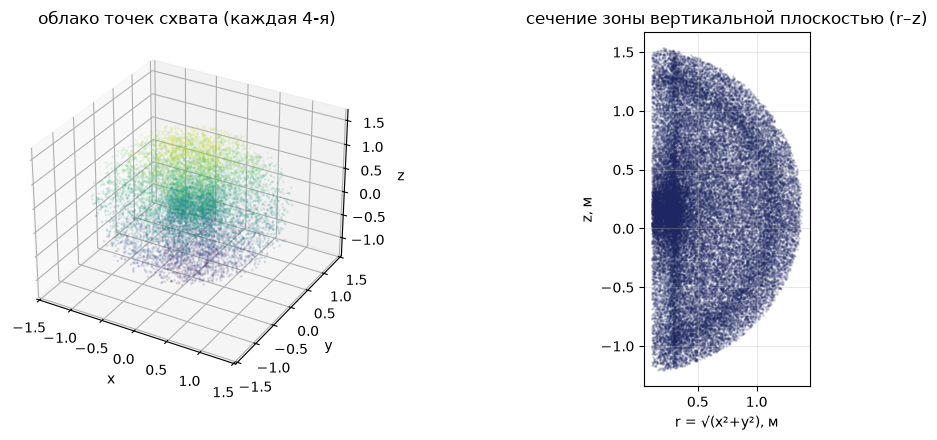

In [5]:
robot = make_ur()
robot.ws_lim = np.array([[-np.pi, np.pi]] * 6)
pts, Q = robot.workspace_random(n=40000, seed=1)

delta = 0.05
cells = set(map(tuple, np.floor(pts / delta).astype(int)))
V = len(cells) * delta**3
L = UR_DH[:, 1].sum() + UR_DH[:, 0].sum()
print('точек: %d, объём V ≈ %.3f м³, L = %.3f м, V_L = V/L³ = %.2f, V_N = V_L/(4π/3) = %.3f' % (len(pts), V, L, V / L**3, V / L**3 / (4*np.pi/3)))
print('пределы досягаемости: R_max = %.3f м, z от %.2f до %.2f' % (np.linalg.norm(pts, axis=1).max(), pts[:,2].min(), pts[:,2].max()))

fig = plt.figure(figsize=(12, 4.5))
ax = fig.add_subplot(1, 2, 1, projection='3d')
ax.scatter(pts[::4, 0], pts[::4, 1], pts[::4, 2], s=1, c=pts[::4, 2], cmap='viridis', alpha=.4)
ax.set_title('облако точек схвата (каждая 4-я)'); ax.set_xlabel('x'); ax.set_ylabel('y'); ax.set_zlabel('z')
ax2 = fig.add_subplot(1, 2, 2)
r = np.hypot(pts[:, 0], pts[:, 1])
ax2.scatter(r, pts[:, 2], s=1, color=NAVY, alpha=.15, rasterized=True)
ax2.set_aspect('equal'); ax2.set_xlabel('r = √(x²+y²), м'); ax2.set_ylabel('z, м'); ax2.grid(alpha=.3)
ax2.set_title('сечение зоны вертикальной плоскостью (r–z)')
plt.tight_layout(); plt.show()

## 5. Коэффициент сервиса плоского 3R (пример 2.8)

Зона обслуживания в точке $\mathbf r$ — множество допустимых направлений оси схвата; коэффициент сервиса $\Omega_r = \psi_r / 2\pi$ (в плоскости).
Точка $O_2$ (конец второго звена) должна лежать в кольце $[l_1 - l_2,\ l_1 + l_2]$: перебираем направления $\varphi$ и считаем долю допустимых.

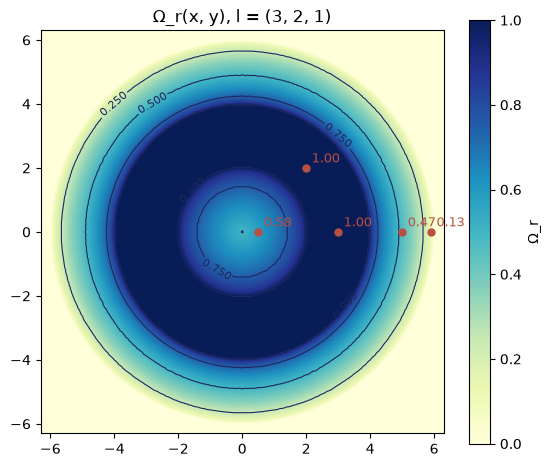

кольцо полного сервиса: 2 ≤ r ≤ 4
сервис манипулятора (среднее Ω_r по площади зоны) ≈ 0.67  (в книге для этого примера приведено 0,48 — оценка по приближённым формулам)


In [6]:
l = (3.0, 2.0, 1.0)      # как в книге: l3 = l1 - l2
xs, Om = service_map_3r(l, N=260, nphi=180)
fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(Om, extent=[xs[0], xs[-1], xs[0], xs[-1]], origin='lower', cmap='YlGnBu', vmin=0, vmax=1)
X, Y = np.meshgrid(xs, xs)
cs = ax.contour(X, Y, Om, levels=[0.25, 0.5, 0.75, 0.999], colors=[NAVY], linewidths=.8); ax.clabel(cs, fontsize=8)
plt.colorbar(im, label='Ω_r'); ax.set_aspect('equal'); ax.set_title('Ω_r(x, y), l = (3, 2, 1)')
for p in [(3.0, 0.0), (5.0, 0.0), (5.9, 0.0), (0.5, 0.0), (2.0, 2.0)]:
    ax.plot(*p, 'o', color=RED, ms=5)
    ax.annotate('%.2f' % service_coefficient_3r(p[0], p[1], l), p, xytext=(4, 4), textcoords='offset points', color=RED, fontsize=9)
plt.show()
print('кольцо полного сервиса: %.0f ≤ r ≤ %.0f' % (l[0]-l[1]+l[2], l[0]+l[1]-l[2]))
print('сервис манипулятора (среднее Ω_r по площади зоны) ≈ %.2f  (в книге для этого примера приведено 0,48 — оценка по приближённым формулам)' % service_average_3r(l, N=260, nphi=120))

## 6. ОЗК двухзвенника: две ветви (пример 2.10)

$\cos q_2 = \dfrac{x^2 + y^2 - l_1^2 - l_2^2}{2 l_1 l_2}$ — два знака $q_2$; $q_1 = \operatorname{atan2}(y, x) - \operatorname{atan2}(l_2 s_2,\ l_1 + l_2 c_2)$.
Каждое решение проверяем прямой задачей.

локоть вверх: q = (6.2°, 75.1°) -> ПЗК даёт (1.100, 0.800)
локоть вниз: q = (65.9°, -75.1°) -> ПЗК даёт (1.100, 0.800)


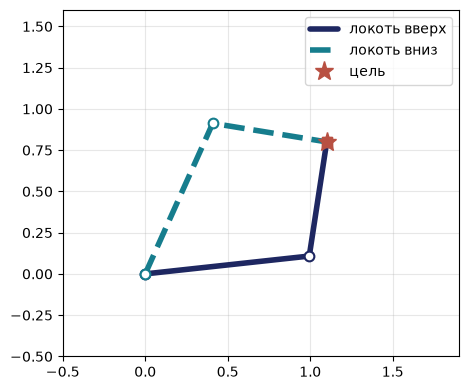

недостижимая цель (2, 1): []


In [7]:
l = (1.0, 0.7)
target = (1.1, 0.8)
sols = ik2r(*target, l)
fig, ax = plt.subplots(figsize=(5.5, 4.5))
for q, col, name in zip(sols, (NAVY, TEAL), ('локоть вверх', 'локоть вниз')):
    p, phi = fk2r(q, l)
    print('%s: q = (%.1f°, %.1f°) -> ПЗК даёт (%.3f, %.3f)' % (name, *np.degrees(q), *p))
    draw_arm2d(ax, q, l, color=col, label=name, ls='-' if col == NAVY else '--')
ax.plot(*target, '*', color=RED, ms=14, label='цель')
ax.set_aspect('equal'); ax.grid(alpha=.3); ax.legend(); ax.set_xlim(-0.5, 1.9); ax.set_ylim(-0.5, 1.6); plt.show()
print('недостижимая цель (2, 1):', ik2r(2.0, 1.0, l))

## 7. Численная ОЗК шестизвенника: сходимость и ветви (п. 2.3.3)

Итерация $\mathbf q_{k+1} = \mathbf q_k + \alpha\, M(\mathbf q_k)\, \mathbf e_k$, где невязка $\mathbf e = (\Delta\mathbf p;\ \delta\boldsymbol\varphi)$, а $M$ — псевдообратная $J^+$, демпфированная $J^{\mathrm T}(JJ^{\mathrm T} + \lambda^2 E)^{-1}$ или транспонированная $J^{\mathrm T}$.
Разные начальные приближения приводят к разным ветвям решения.

псевдообратная J⁺      q* = [134.3 -24.2 -60.1  54.  -90.  -45.7]  достижимо: True
DLS, λ = 0.1           q* = [ 45.7  24.1  60.1 -54.1  90.   45.7]  достижимо: True


ERROR:root:Pose cannot be reached!


транспонированная Jᵀ   q* = [ 44.2  23.8  60.  -53.8  90.   44.2]  достижимо: False


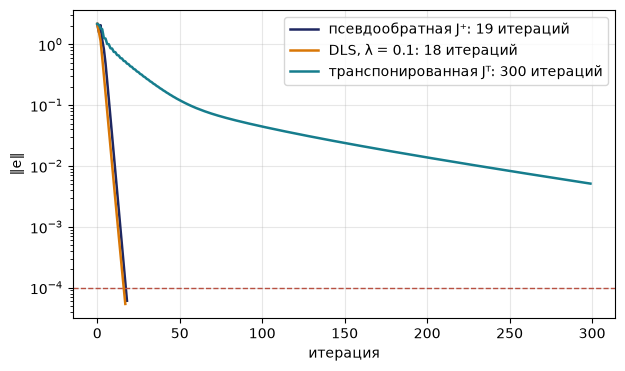

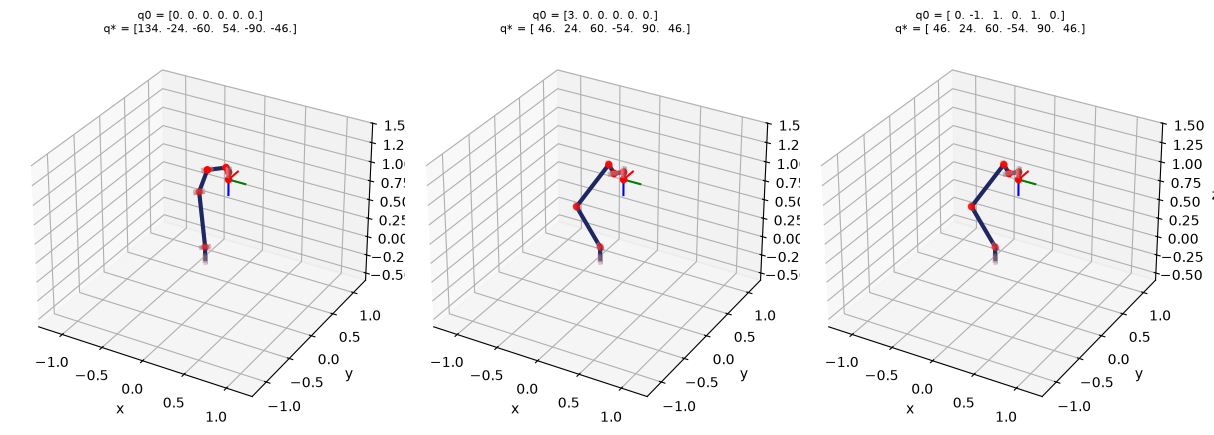

In [8]:
robot = make_ur()
end = Frame.from_euler_3(np.array([0.5*np.pi, 0., np.pi]), np.array([[0.28127], [0.], [1.13182]]))
fig, ax = plt.subplots(figsize=(7, 4))
for m, col, name in (('jac_pinv', NAVY, 'псевдообратная J⁺'), ('jac_dls', AMB, 'DLS, λ = 0.1'), ('jac_t', TEAL, 'транспонированная Jᵀ')):
    robot.inverse_numerical(end, q0=np.zeros(6), method=m, max_iter=300)
    ax.semilogy(robot.inv_history, color=col, lw=1.8, label='%s: %d итераций' % (name, len(robot.inv_history)))
    print('%-22s q* = %s  достижимо: %s' % (name, np.degrees(robot.axis_values).round(1), robot.is_reachable_inverse))
ax.axhline(robot.final_loss, color=RED, ls='--', lw=1); ax.set_xlabel('итерация'); ax.set_ylabel('‖e‖'); ax.grid(alpha=.3); ax.legend(); plt.show()

# разные начальные приближения -> разные конфигурации с одним и тем же положением схвата
fig = plt.figure(figsize=(12, 4.5))
for k, q0 in enumerate((np.zeros(6), np.array([3., 0., 0., 0., 0., 0.]), np.array([0., -1., 1., 0., 1., 0.]))):
    robot.inverse_numerical(end, q0=q0, method='jac_pinv')
    ax = fig.add_subplot(1, 3, k+1, projection='3d')
    robot.draw(ax=ax)
    ax.set_title('q0 = %s\nq* = %s' % (q0.round(1), np.degrees(robot.axis_values).round(0)), fontsize=8)
plt.tight_layout(); plt.show()

## 8. Недостижимая цель и цепочка близких целей (с. 110)

Цель вне зоны: невязка перестаёт убывать, флаг `is_reachable_inverse = False`.
Приём для режима on-line: разбить путь на близкие цели $\mathbf s^0, \dots, \mathbf s^L$ и стартовать каждую из предыдущего ответа — тогда хватает 1–3 итераций на шаг.

In [9]:
robot = make_ur()
far = Frame.from_euler_3(np.array([0.5*np.pi, 0., np.pi]), np.array([[2.2], [0.], [1.9]]))
robot.inverse_numerical(far, q0=np.zeros(6), max_iter=150, verbose=True)
print('достижимо:', robot.is_reachable_inverse, ' последняя невязка %.3f' % robot.inv_history[-1])

# цепочка близких целей: из текущего положения к далёкой, но достижимой цели
robot.forward(np.array([0., -0.5, 0.8, 0., 0.7, 0.]))
s0 = robot.end_frame; sL = Frame.from_euler_3(np.array([0.5*np.pi, 0., np.pi]), np.array([[0.28127], [0.], [1.13182]]))
from scipy.spatial.transform import Rotation, Slerp
slerp = Slerp([0, 1], Rotation.from_matrix(np.stack([s0.r_3_3, sL.r_3_3])))
L = 20; iters = []
for k in range(1, L + 1):
    t = k / L
    target = Frame.from_r_3_3(slerp([t])[0].as_matrix(), (1-t)*s0.t_3_1 + t*sL.t_3_1)
    robot.inverse_numerical(target)                # старт — предыдущее решение
    iters.append(len(robot.inv_history))
print('итераций на каждом шаге цепочки:', iters, ' итого', sum(iters))
robot.inverse_numerical(sL, q0=np.zeros(6)); print('одним прыжком из q0 = 0:', len(robot.inv_history), 'итераций')

ERROR:root:Pose cannot be reached!


достижимо: False  последняя невязка 2.467
итераций на каждом шаге цепочки: [11, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11]  итого 220
одним прыжком из q0 = 0: 19 итераций


## 9. Интерактив: ползунки обобщённых координат (запускать вживую)

In [10]:
try:
    from ipywidgets import interact, FloatSlider
    robot = make_ur()
    def show_q(q1=0., q2=0., q3=-45., q4=0., q5=0., q6=0.):
        T = robot.forward(np.radians([q1, q2, q3, q4, q5, q6]))
        fig = plt.figure(figsize=(6, 6)); ax = fig.add_subplot(111, projection='3d')
        robot.draw(ax=ax); ax.set_title('p = %s' % T.t_3_1.ravel().round(3)); plt.show()
    interact(show_q, **{k: FloatSlider(min=-180, max=180, step=5, value=v) for k, v in zip('q1 q2 q3 q4 q5 q6'.split(), (0, 0, -45, 0, 0, 0))})
except ImportError:
    print('установите ipywidgets: pip install ipywidgets')

interactive(children=(FloatSlider(value=0.0, description='q1', max=180.0, min=-180.0, step=5.0), FloatSlider(v…